<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lesson 03 · Applied AI: unstructured data</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">02.5 · Generative LLMs as classifiers</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">Can a chat model label sentiment with nothing but a prompt?</p>
</div>

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/03-applied-ai-projects/blob/main/01_text_mining/02_project_tweets/02.5_Tweets_Generative_LLMs.ipynb) [![Slides](https://img.shields.io/badge/slides-Lesson_03-ffd43b)](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tweets)

## 🎯 Objectives
By the end of this notebook you will be able to:

- classify text with a **prompt** instead of training a model: Google **Gemini** (through its API) and **Llama-2-7b-chat** (open weights from Hugging Face);
- compare a **simple** prompt with a detailed (**"hard"**) prompt that adds rules and an example;
- measure the LLMs on a labelled **development** set and use them to label an unlabelled **challenge** set;
- look at the reviews where the better prompt made the difference;
- handle **API keys and tokens** safely (environment variables / Colab secrets, never written in the notebook).

**⏱️ Duration:** ≈ 25 min of reading · **📋 Prerequisites:** notebooks 02.0–02.4 · **▶️ How to use:** read top to bottom; run the cells if you like — the LLM calls are switched off and the saved predictions are loaded from `results/`.

> 📝 **Different data in this notebook.** The last step of the tweet project was a *challenge* with a new dataset: **product reviews of laptops written in Brazilian Portuguese** ("notebook" means *laptop* in Brazilian Portuguese). There are **1,500 labelled reviews** (the *development* set, `pos`/`neg`) and **421 unlabelled reviews** (the *challenge* set). The reviews and the prompts are in Portuguese on purpose — English translations are given below. The method is exactly the one you would use for tweets.

> ⏳ **Heavy cells.** Calling Gemini needs an API key and is rate-limited (≈ 15–50 min per run); Llama-2-7b is a 13.5 GB download that needs a big GPU. Both are **off by default** (`run_gemini = False`, `run_llama2 = False`); the saved predictions come from the original runs.

*Based on the Text Mining project by Diogo Freitas, João Francisco Botas and Ana Sofia Trabulo (ISCTE, 2024/25).*

## 📑 Contents

- [⚙️ Setup](#setup)
0. [📥 Reading the data](#sec-0)
1. [✨ Generative model: Gemini](#sec-1)
2. [🦙 Generative model: Llama-2-7b from Hugging Face](#sec-2)
   - [2.3. ☁️ The Colab run (Tesla T4)](#sec-2-3)
3. [📊 Results](#sec-3)
4. [🏆 Comparing the results](#sec-4)
- [📌 Summary](#summary)

<a id="setup"></a>

## ⚙️ Setup

Imports and paths. The small data files of this notebook (the challenge reviews and the saved predictions) live in `results/`, next to the notebook.

In [34]:
# ⚙️ Setup: works locally (VS Code / Jupyter) and in Google Colab
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/03-applied-ai-projects")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/the-ai-learning-hub/03-applied-ai-projects.git", str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "google-generativeai"], check=True)
else:  # locally: walk up until we find the folder that has src/ and data/
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())
sys.path.insert(0, str(ROOT))

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from tqdm import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer, GenerationConfig, pipeline

try:
    import google.generativeai as genai  # only needed to call Gemini again: pip install google-generativeai
except ImportError:
    genai = None

pd.set_option('display.max_colwidth', None)  # show the full text
RESULTS = ROOT / "01_text_mining" / "02_project_tweets" / "results"  # reviews + saved LLM predictions

print("Project root:", ROOT.name, "(Colab)" if IN_COLAB else "(local)")

Project root: 03-applied-ai-projects (local)


### 🔑 Access to the keys / tokens

- Gemini: https://aistudio.google.com/apikey
- Hugging Face: https://huggingface.co/settings/tokens

> 🔒 **Never write a key in a notebook** (it ends up in git and in the outputs). Set it as an environment variable before starting Jupyter (`GEMINI_API_KEY`, `HF_TOKEN`) or, in Colab, add it in the 🔑 *Secrets* panel on the left. You only need them to re-run the LLM calls.

In [35]:
# Read the keys from environment variables, or from Colab secrets
def get_secret(name):
    value = os.environ.get(name, "")
    if not value and IN_COLAB:
        try:
            from google.colab import userdata
            value = userdata.get(name) or ""
        except Exception:
            value = ""
    return value

GEMINI_KEY = get_secret("GEMINI_API_KEY")  # https://aistudio.google.com/apikey
HF_TOKEN = get_secret("HF_TOKEN")

print("GEMINI_KEY:", GEMINI_KEY[:2] + "..." if GEMINI_KEY else "Not set")
print("HF_TOKEN:", HF_TOKEN[:2] + "..." if HF_TOKEN else "Not set")

GEMINI_KEY: Not set
HF_TOKEN: Not set


### Helper functions

The confusion matrix and the performance report shared by the whole project (`src/tweet_tools.py`).

In [36]:
from src.tweet_tools import plot_confusion_matrix, print_classification_report

<a id="sec-0"></a>

## 0. 📥 Reading the data

The **development** set: 1,500 reviews with their label (`sentiment`).

In [37]:
# Development set: 1,500 labelled reviews. The original project read them from "notebooks-devel.csv"
# (tab-separated, not shipped here); the same two columns are the first columns of the saved prediction files.
devel = pd.read_csv(RESULTS / "notebook-develop_llama2-hard.csv", usecols=["sentiment", "review_text"])
devel

,sentiment,review_text
0,pos,Estou contente com a compra entrega rápida o único problema com as <empresa> é se houver troca ou devolução do produto o consumidor tem problemas com espera.
1,pos,"Excelente!!! Produto muito bom, bonito, design super moderno. De ótima qualidade! Gostei muito!"
2,pos,"Superou expectativas É excelente para jogos, super rápido tela full hd tamanho ideal leve e Pratico"
3,pos,"Comprei o mesmo para minha irmã e ela me contou que ele é ótimo, rápido e a imagem é muito bonita. Tive oportunidade de mexer com ele e realmente ele cumpre com o que disse. Recomendo demais para quem estuda ou trabalha com um. Obrigado a <empresa> e a Asus!"
4,pos,Notebbok muito bom! Rápido pequeno e leve para quem quer um notebook com um bom desempenho e que oculpa pouco espaço ele é perfeito. A autonomia da bateria é muito boa. Ele liga e desliga muito rápido.
...,...,...
1495,neg,"Fiz a compra dia 12/04/2018 era pra ter chegado dia 30/04/2018 e chegou hoje 19/04/2018 a entrega foi super rápida. Porém o notebook travou muito, sistema operacional não é dos melhores (Linux). Mais em questão a isso vou instalar o Windows 10. E o atendimento foi perfeito!"
1496,pos,"excelente produto foi além da minha expectativa , pode comprar sem medo"
1497,pos,"Produto atendeu as expectativas estava conforme o anúncio, veio bem embalado"
1498,pos,Ótimo produto vei tudo certo e rapido notbook impecável ótimo custo beneficio


In [38]:
devel_reviews = devel['review_text'].tolist()
devel_labels = devel['sentiment'].tolist()

# devel_reviews

The **challenge** set: 421 reviews **without** labels (one per line, after a header line).

In [39]:
with open(RESULTS / 'notebooks-challenge.txt', encoding='utf-8') as f:
    reviews = [line.strip() for line in f.readlines()[1:]] # the 1st line is the header

reviews[:5]

['O note é bom, mas não superou as expectativas quanto a velocidade, por isso sugiro 8GB',
 'Ele corresponde ao valor pago. Custando em média R$ 2000, não encontraremos nada melhor.',
 'O notebook é muito bom, o Windows 10 ferra um pouco com a velocidade, mas isso é coisa do sistema operacional. Recomendo muito esse produto.',
 'O notebook tem uma tela enorme, muito útil para trabalhar e fazer trabalhos acadêmicos. É lindo...',
 'Muito bom ! Excelente notebook! Entrega rapida. Fiquei muito satisfeita.']

> 🔎 English versions of the first reviews, to get a feel for the data: *"The laptop is good, but it did not meet expectations on speed, so I suggest 8GB"* · *"It matches the price paid. Costing about R$ 2000, we won't find anything better."* · *"The laptop is very good, Windows 10 slows it down a bit, but that's the operating system…"*. Mixed opinions like the first one are what makes this hard.

### Turn on the GPU for the generative models

In [40]:
import torch
import torch.nn.functional as F

if torch.cuda.is_available():
    device = torch.device("cuda")
    gpu_name = torch.cuda.get_device_name(device)
    total_mem = round(torch.cuda.get_device_properties(device).total_memory / 1024**3, 2)  # GB
    print("🚀 GPU detected!")
    print(f"🖥️ Device in use: {device}")
    print(f"📛 GPU name: {gpu_name}")
    print(f"💾 Total memory: {total_mem} GB")
else:
    device = torch.device("cpu")
    print("⚠️ No GPU available. Running on CPU.")

⚠️ No GPU available. Running on CPU.


<a id="sec-1"></a>

## 1. ✨ Generative model: Gemini

The limits of each model are listed here: https://ai.google.dev/gemini-api/docs/rate-limits

- Gemini 1.5 flash: **15** RPM (requests per minute)
- Gemini 2.0 flash lite: **30** RPM

> 💡 These were the free-tier models when the project was made (2025). Model names and the Python SDK change quickly; if a call fails, check the current model list and SDK in the Gemini API docs.

In [41]:
# Supported models
GEN_MODELS = {
    "gemini-1.5-flash": {
        "model_id": "gemini-1.5-flash",
        "rpm": 15
    },
    "gemini-2.0-flash-lite": {
        "model_id": "models/gemini-2.0-flash-lite",
        "rpm": 30
    }
}

# Prompts (in Portuguese, like the reviews - see the English translation below)
PROMPTS = {
    "simple": lambda review: f"""
Classifica o sentimento da seguinte review de notebook como "pos" (positivo) ou "neg" (negativo).
Responde para cada uma das frases com apenas uma palavra: pos ou neg.

Review: "{review}"
Sentimento:""",

    "hard": lambda review: f"""
És um modelo de linguagem especializado em análise de sentimentos de reviews de produtos.
A tua tarefa é classificar o sentimento expresso numa review de notebook como "pos" (positivo) ou "neg" (negativo).

Segue as regras seguintes:
- Responde sempre com apenas uma palavra: "pos" ou "neg" ;
- Considera o tom geral da review (mesmo que haja elogios ou críticas mistas);
- Usa bom senso para interpretar se a experiência do utilizador foi maioritariamente positiva ou negativa.

Exemplo:
Review: "Gostei muito do desempenho, mas o teclado poderia ser melhor."
Sentimento: pos

Agora analisa a seguinte review:

Review: "{review}"
Sentimento:"""
}

**The two prompts in English** (the code keeps the Portuguese originals, because those produced the saved results):

| `simple` | `hard` |
|---|---|
| *Classify the sentiment of the following laptop review as "pos" (positive) or "neg" (negative). Answer each sentence with a single word: pos or neg.*<br><br>*Review: "{review}"*<br>*Sentiment:* | *You are a language model specialised in sentiment analysis of product reviews. Your task is to classify the sentiment expressed in a laptop review as "pos" (positive) or "neg" (negative).*<br><br>*Follow these rules:*<br>*- Always answer with a single word: "pos" or "neg";*<br>*- Consider the overall tone of the review (even with mixed praise or criticism);*<br>*- Use common sense to judge whether the user's experience was mostly positive or negative.*<br><br>*Example:*<br>*Review: "I really liked the performance, but the keyboard could be better."*<br>*Sentiment: pos*<br><br>*Now analyse the following review:*<br>*Review: "{review}"*<br>*Sentiment:* |

The "hard" prompt gives the model a **role**, explicit **rules** and **one example** (*one-shot* prompting). Both end with `Sentiment:` so the model only has to complete one word.

### 1.1. Gemini on the `challenge.txt` reviews (no labels)

⏳ Heavy: ~15 min through the Gemini API (421 reviews at ≤ 30 requests/min, needs a key) — the saved predictions come from the original run; you do not need to re-run it. With `run_gemini = False` this cell only defines the function.

In [ ]:
##################################################################
run_gemini = False  # True = call the API again (slow, needs GEMINI_API_KEY)
model_choice = "gemini-2.0-flash-lite"  # or "gemini-1.5-flash"
prompt_type = "hard"  # or "simple"
##################################################################

rpm = GEN_MODELS[model_choice]["rpm"]
if run_gemini:
    genai.configure(api_key=GEMINI_KEY)  # API key from the environment (see the 🔑 cell)
    model = genai.GenerativeModel(GEN_MODELS[model_choice]["model_id"])

with open(RESULTS / 'notebooks-challenge.txt', encoding='utf-8') as f:
    reviews = [line.strip() for line in f.readlines()[1:]]  # skip the header

# Classification function
def classify_with_gemini(review):
    prompt = PROMPTS[prompt_type](review)
    try:
        response = model.generate_content(prompt)
        label = response.text.strip().lower()
        return 'pos' if 'pos' in label else 'neg'  # fallback
    except Exception as e:
        print(f"Error: {e}")
        return 'pos'


if run_gemini:
    # Classification
    results = []
    for i, review in enumerate(tqdm(reviews)):
        label = classify_with_gemini(review)
        results.append(label)
        time.sleep((60/rpm) - 0.1)  # stay under the requests-per-minute limit

    # Save the results
    df = pd.DataFrame({
        'sentiment': results,
        'review_text': reviews
    })

    filename = f"notebook-challenge_{model_choice.replace('models/', '')}_{prompt_type}.csv"
    df.to_csv(RESULTS / filename, index=False)

    print(f"✅ Results saved to '{filename}'.")

> ⚠️ **Limitation:** the answer parsing has silent defaults. If the API call fails (rate limit, network, blocked content) the function returns `'pos'`, and any answer that does not contain "pos" becomes `'neg'` (the Llama-2 function below does the opposite: anything without "neg" becomes `'pos'`). Errors are therefore counted as real predictions and can bias the scores towards one class. A safer version returns a separate `'unknown'` label, counts how often it happens and retries those reviews.

### 1.2. Test Gemini on the `devel.csv` reviews (with labels, to measure accuracy)

⏳ Heavy: ~50 min through the Gemini API (1,500 reviews at ≤ 30 requests/min) — the saved predictions from the original run are loaded in section 3; you do not need to re-run it.

In [ ]:
if run_gemini:
    pred_labels = []

    for review in tqdm(devel_reviews): # here we use the devel_reviews!
        pred = classify_with_gemini(review)
        pred_labels.append(pred)
        time.sleep((60 / rpm) - 0.1)

    devel[f"{model_choice}_prediction"] = pred_labels

    plot_confusion_matrix(devel_labels, pred_labels, model_name=model_choice)
    print_classification_report(devel_labels, pred_labels, model_name=model_choice)
    devel.to_csv(RESULTS / f"notebook-develop_{model_choice.replace('models/', '')}_{prompt_type}.csv", index=False)

<a id="sec-2"></a>

## 2. 🦙 Generative model: Llama-2-7b from Hugging Face

An **open-weights** chat model with 7 billion parameters that runs on our own GPU — no API, no rate limit, but a big download. `NousResearch/Llama-2-7b-chat-hf` is a public copy of Meta's Llama-2-7b-chat.

### 2.1. Llama-2-7b on the `challenge.txt` reviews (no labels)

⏳ Heavy: ~7 min on a GPU with ≥ 14 GB (plus a 13.5 GB download) for the 421 reviews — the saved output of the original run is in section 2.3; you do not need to re-run it.

In [ ]:
# Hugging Face token (from the 🔑 cell) -> https://huggingface.co/settings/tokens
hf_token = HF_TOKEN or None
model_id = "NousResearch/Llama-2-7b-chat-hf"
if hf_token:
    os.environ["HF_TOKEN"] = hf_token

#########################################
run_llama2 = False  # True = download the model and classify again (needs a big GPU)
prompt_type = "hard"  # or "simple"
model_name = "llama2"
#########################################

# Classify one review with Llama-2
def classify_sentiment_llama(review, prompt_type="simple"):
    prompt = PROMPTS[prompt_type](review)

    try:
        output = generator(prompt, max_new_tokens=10, temperature=0.1, do_sample=False)
        response = output[0]["generated_text"].split("Sentimento:")[-1].strip().lower()
        if "neg" in response:
            return "neg"
        return "pos"
    except Exception as e:
        print(f"Error while classifying: {e}")
        return "pos"

if run_llama2:

    tokenizer = AutoTokenizer.from_pretrained(model_id, token=hf_token)
    model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32, token=hf_token)

    # Text-generation pipeline
    generator = pipeline("text-generation", model=model, tokenizer=tokenizer)

    # Classification
    results = []
    for i, review in enumerate(tqdm(reviews)):
        short_preview = review[:30] + ("..." if len(review) > 30 else "")
        print(f"🔍 \033[1mAnalysing review\033[0m {i+1}/{len(reviews)}: \"{short_preview}\"")

        label = classify_sentiment_llama(review, prompt_type=prompt_type)
        print(f"➡️ \033[1mPrediction\033[0m: {label.upper()}\n")

        results.append(label)
        time.sleep(0.7) # do not go too fast; adjust!


    df = pd.DataFrame({
        'sentiment': results,
        'review_text': reviews
    })

    filename = f"notebook-challenge_{model_name}_{prompt_type}.csv"
    df.to_csv(RESULTS / filename, index=False)

> 💡 The model's answer contains the whole prompt followed by the generated words, so the code keeps only the text after the last `Sentimento:` (*Sentiment:*) and looks for `neg` in it.

### 2.2. Test Llama-2-7b on the `devel.csv` reviews (with labels, to measure accuracy)

⏳ Heavy: ~25 min on a GPU with ≥ 14 GB for the 1,500 reviews — the saved output of the original run is in section 2.3; you do not need to re-run it.

In [ ]:
if run_llama2:
    pred_labels = []

    for i, review in enumerate(tqdm(devel_reviews)):
        short_preview = review[:30] + ("..." if len(review) > 30 else "")
        print(f"🔍 \033[1mAnalysing review\033[0m {i+1}/{len(devel_reviews)}: \"{short_preview}\"")

        pred = classify_sentiment_llama(review, prompt_type=prompt_type)
        print(f"➡️ \033[1mPrediction\033[0m: {pred.upper()}\n")

        pred_labels.append(pred)
        time.sleep(0.7) # do not go too fast; adjust!

    devel["llama2_prediction"] = pred_labels

    model_name = f"LLaMA2 ({prompt_type})"
    plot_confusion_matrix(devel_labels, pred_labels, model_name=model_name)
    print_classification_report(devel_labels, pred_labels, model_name=model_name)
    devel.to_csv(RESULTS / f"notebook-develop_llama2-{prompt_type}.csv", index=False)

<a id="sec-2-3"></a>

### 2.3. ☁️ The Colab run (Tesla T4)

> ⚙️ **This part was developed to run on [Google Colab](https://colab.research.google.com/).**
>
> It is a variation of sections 2.1–2.2 with small changes for Colab: the data files sit next to the notebook, the evaluation functions were defined inline (the same as `src/tweet_tools.py`), and the model is loaded before the classification loop. A GPU runtime is recommended (menu *Runtime* > *Change runtime type* > *GPU*) for the language models.
>
> The outputs below are the real Llama-2 run with the **hard** prompt on a free **Tesla T4**: ≈ 7 min for the 421 challenge reviews and ≈ 25 min for the 1,500 development reviews. The long per-review logs are shortened.

In [6]:
import torch
from transformers import pipeline, AutoTokenizer, AutoModelForSequenceClassification
import torch.nn.functional as F

if torch.cuda.is_available():
    device = torch.device("cuda")
    gpu_name = torch.cuda.get_device_name(device)
    total_mem = round(torch.cuda.get_device_properties(device).total_memory / 1024**3, 2)  # GB
    print("🚀 GPU detected!")
    print(f"🖥️ Device in use: {device}")
    print(f"📛 GPU name: {gpu_name}")
    print(f"💾 Total memory: {total_mem} GB")
else:
    device = torch.device("cpu")
    print("⚠️ No GPU available. Running on CPU.")

🚀 GPU detected!
🖥️ Device in use: cuda
📛 GPU name: Tesla T4
💾 Total memory: 14.74 GB


⏳ Heavy: ~7 min on a Tesla T4 (plus a 13.5 GB download) — the saved output below comes from the original run; you do not need to re-run it.

In [ ]:
# Hugging Face token (from the 🔑 cell) -> https://huggingface.co/settings/tokens
hf_token = HF_TOKEN or None
model_id = "NousResearch/Llama-2-7b-chat-hf"

#########################################
run_llama2 = False  # the original Colab run used True
prompt_type = "hard"  # or "simple"
model_name = "llama2"
#########################################

if run_llama2:
    # newer transformers versions: use token=hf_token (use_auth_token gives the FutureWarning below)
    tokenizer = AutoTokenizer.from_pretrained(model_id, use_auth_token=hf_token)
    model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32, use_auth_token=hf_token)

    # Text-generation pipeline
    generator = pipeline("text-generation", model=model, tokenizer=tokenizer)

# Classify one review with Llama-2
def classify_sentiment_llama(review, prompt_type="simple"):
    prompt = PROMPTS[prompt_type](review)

    try:
        output = generator(prompt, max_new_tokens=10, temperature=0.1, do_sample=False)
        response = output[0]["generated_text"].split("Sentimento:")[-1].strip().lower()
        if "neg" in response:
            return "neg"
        return "pos"
    except Exception as e:
        print(f"Error while classifying: {e}")
        return "pos"

if run_llama2:
    # Classification
    results = []
    for i, review in enumerate(tqdm(reviews)):
        short_preview = review[:30] + ("..." if len(review) > 30 else "")
        print(f"🔍 \033[1mAnalysing review\033[0m {i+1}/{len(reviews)}: \"{short_preview}\"")

        label = classify_sentiment_llama(review, prompt_type=prompt_type)
        print(f"➡️ \033[1mPrediction\033[0m: {label.upper()}\n")

        results.append(label)
        time.sleep(0.7) # do not go too fast; adjust!


    df = pd.DataFrame({
        'sentiment': results,
        'review_text': reviews
    })

    filename = f"notebook-challenge_{model_name}_{prompt_type}.csv"
    df.to_csv(RESULTS / filename, index=False)

/usr/local/lib/python3.11/dist-packages/transformers/models/auto/tokenization_auto.py:897: FutureWarning: The `use_auth_token` argument is deprecated and will be removed in v5 of Transformers. Please use `token` instead.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/746 [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/21.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/435 [00:00<?, ?B/s]

... (7 outputs left out)

generation_config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Device set to use cuda:0
  0%|          | 0/421 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.1` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.6` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(


🔍 Analysing review 1/421: "O note é bom, mas não superou ..."
➡️ Prediction: POS

🔍 Analysing review 2/421: "Ele corresponde ao valor pago...."
➡️ Prediction: NEG

🔍 Analysing review 3/421: "O notebook é muito bom, o Wind..."
➡️ Prediction: POS

🔍 Analysing review 4/421: "O notebook tem uma tela enorme..."
➡️ Prediction: POS

🔍 Analysing review 5/421: "Muito bom ! Excelente notebook..."
➡️ Prediction: POS

🔍 Analysing review 6/421: "Excelente, é tudo de bom, já t..."
➡️ Prediction: POS

🔍 Analysing review 7/421: "Excelente produto superou toda..."
➡️ Prediction: POS

🔍 Analysing review 8/421: "Ótima relação custo/benefício...."
➡️ Prediction: POS

🔍 Analysing review 9/421: "produto chegou com defeito e a..."
➡️ Prediction: NEG

🔍 Analysing review 10/421: "Compra segura, entrega eficien..."
➡️ Prediction: POS

[... log of reviews 11-418 omitted to keep the notebook light ...]

🔍 Analysing review 419/421: "Gostei muito, além de lindo, é..."
➡️ Prediction: POS

🔍 Analysing review 420/421:

100%|██████████| 421/421 [07:00<00:00,  1.00it/s]



⏳ Heavy: ~25 min on a Tesla T4 for the 1,500 development reviews — the saved output below comes from the original run; you do not need to re-run it.

  0%|          | 0/1500 [00:00<?, ?it/s]

🔍 Analysing review 1/1500: "Estou contente com a compra en..."
➡️ Prediction: POS

🔍 Analysing review 2/1500: "Excelente!!! Produto muito bom..."
➡️ Prediction: POS

🔍 Analysing review 3/1500: "Superou expectativas  É excele..."
➡️ Prediction: POS

🔍 Analysing review 4/1500: "Comprei o mesmo para minha irm..."
➡️ Prediction: POS

🔍 Analysing review 5/1500: "Notebbok muito bom! Rápido peq..."
➡️ Prediction: POS

🔍 Analysing review 6/1500: "Ótimo custo-benefício, abre to..."
➡️ Prediction: POS

🔍 Analysing review 7/1500: "O produto atendeu minha expect..."
➡️ Prediction: POS

🔍 Analysing review 8/1500: "Muito bom o produto, quem está..."
➡️ Prediction: POS

🔍 Analysing review 9/1500: "Inicialmente gostaria de dizer..."
➡️ Prediction: POS

🔍 Analysing review 10/1500: "Equipamento muito bom utilizo ..."
➡️ Prediction: POS

[... log of reviews 11-1497 omitted to keep the notebook light ...]

🔍 Analysing review 1498/1500: "Produto atendeu as expectativa..."
➡️ Prediction: POS

🔍 Analysing re

100%|██████████| 1500/1500 [24:52<00:00,  1.01it/s]



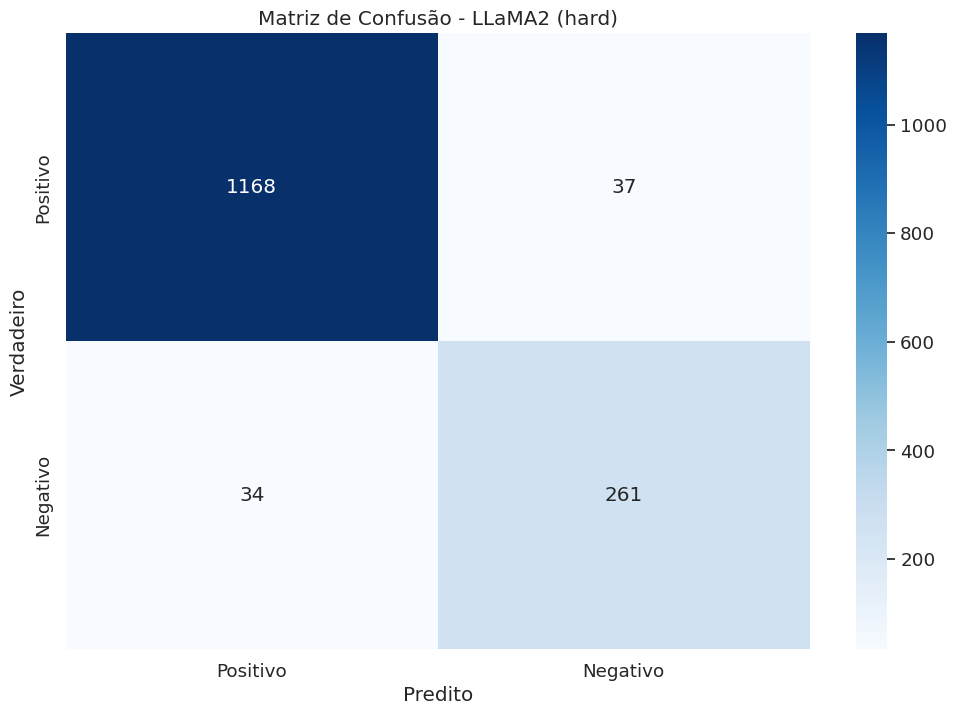


=== Performance report: LLaMA2 (hard) ===
Accuracy : 0.9527
Precision: 0.9717
Recall   : 0.9693
F1-score : 0.9705

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.88      0.88      0.88       295
         pos       0.97      0.97      0.97      1205

    accuracy                           0.95      1500
   macro avg       0.92      0.93      0.93      1500
weighted avg       0.95      0.95      0.95      1500



In [11]:
if run_llama2:
    pred_labels = []

    for i, review in enumerate(tqdm(devel_reviews)):
        short_preview = review[:30] + ("..." if len(review) > 30 else "")
        print(f"🔍 \033[1mAnalysing review\033[0m {i+1}/{len(devel_reviews)}: \"{short_preview}\"")

        pred = classify_sentiment_llama(review, prompt_type=prompt_type)
        print(f"➡️ \033[1mPrediction\033[0m: {pred.upper()}\n")

        pred_labels.append(pred)
        time.sleep(0.7) # do not go too fast; adjust!

    devel["llama2_prediction"] = pred_labels

    model_name = f"LLaMA2 ({prompt_type})"
    plot_confusion_matrix(devel_labels, pred_labels, model_name=model_name)
    print_classification_report(devel_labels, pred_labels, model_name=model_name)
    devel.to_csv(RESULTS / f"notebook-develop_llama2-{prompt_type}.csv", index=False)

<a id="sec-3"></a>

## 3. 📊 Results

We load the saved predictions of the three runs on the development set and compare them with the true labels.

In [42]:
llama_hard, llama_simple = (pd.read_csv(RESULTS / "notebook-develop_llama2-hard.csv"), pd.read_csv(RESULTS / "notebook-develop_llama2-simple.csv"))
gemini_hard = pd.read_csv(RESULTS / "notebook-develop_gemini-2.0-flash-lite_hard.csv")

# rename the prediction columns
llama_hard.rename(columns={"llama2_prediction": "LLama_hard_prediction"}, inplace=True)
llama_simple.rename(columns={"llama2_prediction": "LLama_simple_prediction"}, inplace=True)

# join the two dataframes on sentiment and review_text
llama = pd.merge(llama_hard, llama_simple, on=["sentiment", "review_text"])
llama

,sentiment,review_text,LLama_hard_prediction,LLama_simple_prediction
0,pos,Estou contente com a compra entrega rápida o único problema com as <empresa> é se houver troca ou devolução do produto o consumidor tem problemas com espera.,pos,pos
1,pos,"Excelente!!! Produto muito bom, bonito, design super moderno. De ótima qualidade! Gostei muito!",pos,pos
2,pos,"Superou expectativas É excelente para jogos, super rápido tela full hd tamanho ideal leve e Pratico",pos,pos
3,pos,"Comprei o mesmo para minha irmã e ela me contou que ele é ótimo, rápido e a imagem é muito bonita. Tive oportunidade de mexer com ele e realmente ele cumpre com o que disse. Recomendo demais para quem estuda ou trabalha com um. Obrigado a <empresa> e a Asus!",pos,pos
4,pos,Notebbok muito bom! Rápido pequeno e leve para quem quer um notebook com um bom desempenho e que oculpa pouco espaço ele é perfeito. A autonomia da bateria é muito boa. Ele liga e desliga muito rápido.,pos,pos
...,...,...,...,...
1495,neg,"Fiz a compra dia 12/04/2018 era pra ter chegado dia 30/04/2018 e chegou hoje 19/04/2018 a entrega foi super rápida. Porém o notebook travou muito, sistema operacional não é dos melhores (Linux). Mais em questão a isso vou instalar o Windows 10. E o atendimento foi perfeito!",pos,pos
1496,pos,"excelente produto foi além da minha expectativa , pode comprar sem medo",pos,pos
1497,pos,"Produto atendeu as expectativas estava conforme o anúncio, veio bem embalado",pos,pos
1498,pos,Ótimo produto vei tudo certo e rapido notbook impecável ótimo custo beneficio,pos,pos


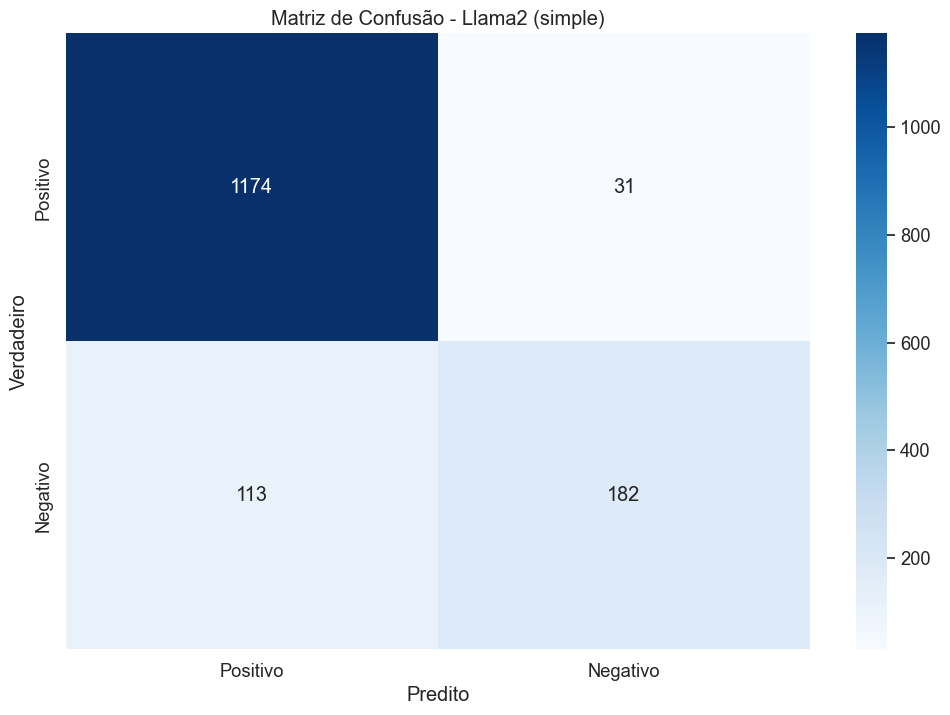

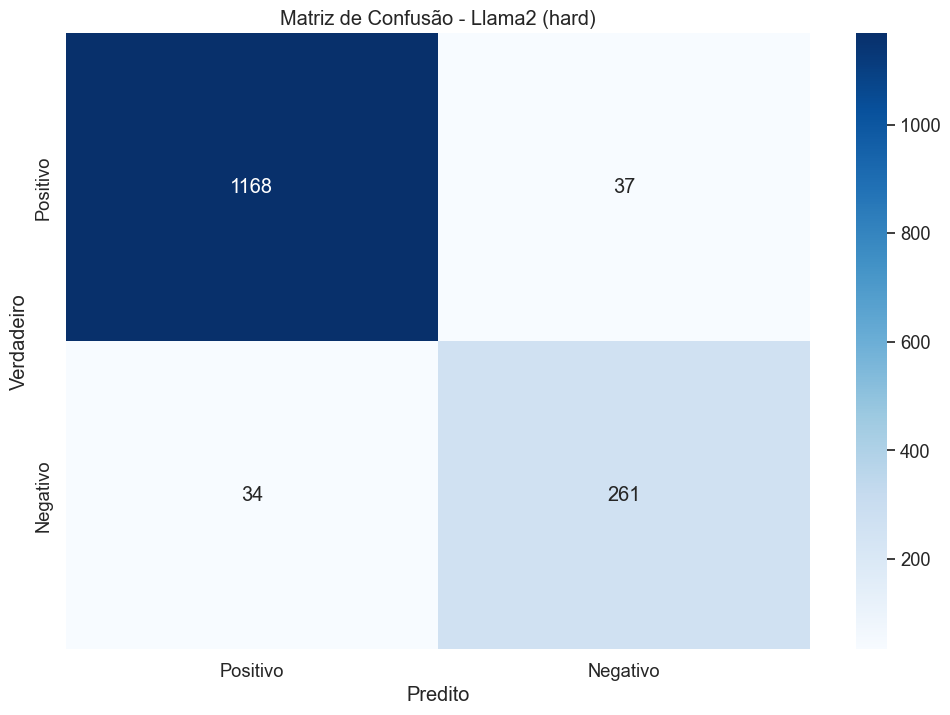

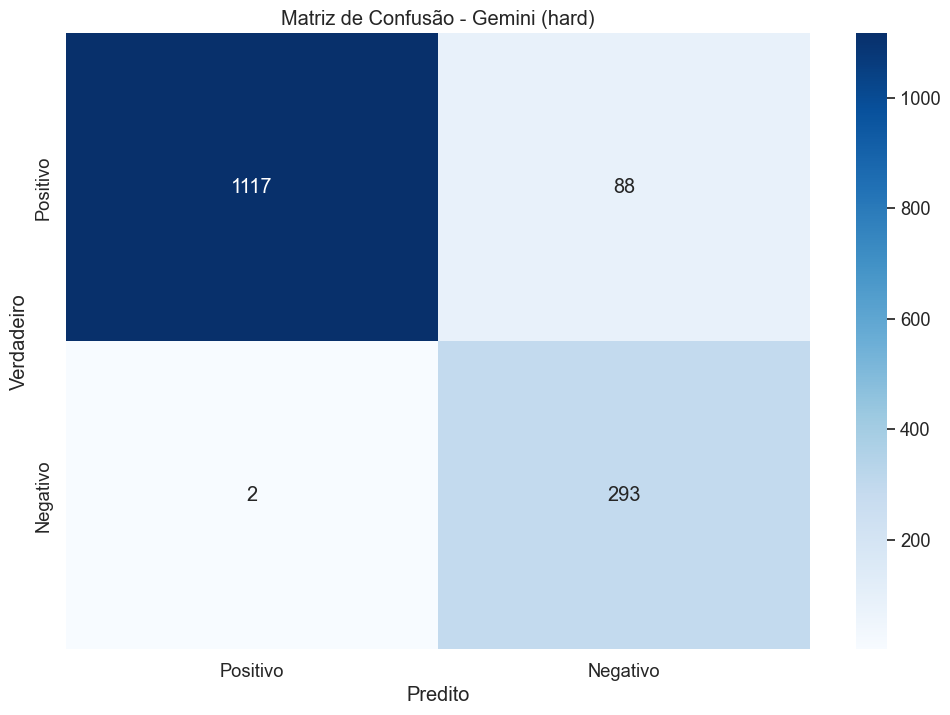

In [43]:
plot_confusion_matrix(llama["sentiment"], llama["LLama_simple_prediction"], model_name="Llama2 (simple)")
plot_confusion_matrix(llama["sentiment"], llama["LLama_hard_prediction"], model_name="Llama2 (hard)")
plot_confusion_matrix(gemini_hard["sentiment"], gemini_hard["gemini-2.0-flash-lite_prediction"], model_name="Gemini (hard)")

In [44]:
print_classification_report(llama["sentiment"], llama["LLama_simple_prediction"], model_name="Llama2 (simple)")
print_classification_report(llama["sentiment"], llama["LLama_hard_prediction"], model_name="Llama2 (hard)")
print_classification_report(gemini_hard["sentiment"], gemini_hard["gemini-2.0-flash-lite_prediction"], model_name="Gemini (hard)")


=== Performance report: Llama2 (simple) ===
Accuracy : 0.9040
Precision: 0.9122
Recall   : 0.9743
F1-score : 0.9422

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.85      0.62      0.72       295
         pos       0.91      0.97      0.94      1205

    accuracy                           0.90      1500
   macro avg       0.88      0.80      0.83      1500
weighted avg       0.90      0.90      0.90      1500


=== Performance report: Llama2 (hard) ===
Accuracy : 0.9527
Precision: 0.9717
Recall   : 0.9693
F1-score : 0.9705

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.88      0.88      0.88       295
         pos       0.97      0.97      0.97      1205

    accuracy                           0.95      1500
   macro avg       0.92      0.93      0.93      1500
weighted avg       0.95      0.95      0.95      1500


=== Performance report: Gemini (hard) ===
Accuracy : 0.9400
Pre

> 🔎 **What to notice:**
> - With **no training at all**, the LLMs reach **0.90–0.95 accuracy** on the 1,500 labelled reviews.
> - The **prompt matters**: the same Llama-2 goes from 0.9040 (simple) to **0.9527** (hard), and its `neg` recall from 0.62 to 0.88.
> - **Gemini (hard)** almost never misses a negative review (`neg` recall **0.99**) but calls some positive reviews negative (`pos` recall 0.93) — it errs on the other side.

> ⚠️ **Limitation:** the summary lines (Precision / Recall / F1) are computed **only for the majority class `pos`** (1,205 of the 1,500 reviews). They look excellent even for the simple prompt (F1 0.9422), while the detailed report shows it finds only **62%** of the negative reviews. Read the `neg` row and the *macro avg* row too.

With the simple prompt the model misclassifies 113+31=144 texts, while with the more complete prompt it gets 34+37=71 texts wrong.

In [45]:
# rows where the hard prompt is right and the simple prompt is wrong
lines_Rhard_WSimple = llama[
    (llama["LLama_hard_prediction"] == llama["sentiment"]) &
    (llama["LLama_simple_prediction"] != llama["sentiment"])
]
# rows where the hard prompt is wrong and the simple prompt is right
lines_Whard_RSimple = llama[
    (llama["LLama_hard_prediction"] != llama["sentiment"]) &
    (llama["LLama_simple_prediction"] == llama["sentiment"])
]

print(f"Rows that Llama2 (hard) got right and Llama2 (simple) got wrong: {lines_Rhard_WSimple.shape[0]}")
print(f"Rows that Llama2 (hard) got wrong and Llama2 (simple) got right: {lines_Whard_RSimple.shape[0]}")

Rows that Llama2 (hard) got right and Llama2 (simple) got wrong: 101
Rows that Llama2 (hard) got wrong and Llama2 (simple) got right: 28


> 🔎 The better prompt is not better on *every* review: it fixes 101 reviews but breaks 28 that the simple prompt got right. The net gain is 101 − 28 = 73 fewer errors (144 → 71).

In [46]:
lines_Rhard_WSimple

,sentiment,review_text,LLama_hard_prediction,LLama_simple_prediction
35,neg,"O Notebook foi um presente de Natal para minha filha. Nós o recebemos no dia 22/12 e, neste dia, funcionou sem problemas. No dia seguinte (23/12) o Note não ligou. Mesmo estando com a bateria carregada, só funcionava quando conectado na tomada.",neg,pos
36,pos,"até então, perfeito. Tudo que pretendia com ele, fiz........",pos,neg
59,neg,"Comprei o notebook,e no segundo dia de uso ele não liga mais,fora o transtorno da coleta que ainda não foi feita.",neg,pos
62,neg,O produto nem sequer iniciou....estou insatisfeita. Reinicia automaticamente e constantemente. ..Estou tentando a troca ou devolução do produto...no momento aguardando um retorno da <empresa> sobre minha solicitação. ..,neg,pos
67,neg,"Usei o produto só algumas vezes durante um período de menos um mês que recebi em minha casa dia 13 de dezembro guardei o computador e quando fui usar novamente no dia 30 ele já deu pau, ou seja o sistema operacional não abre mais.",neg,pos
...,...,...,...,...
1443,neg,Ele é lento demais.A bateria dura no maximo 2 horas.Com um ano e meio de uso ele quebrou e não compensava arrumar.É o barato que sai caro.Compensa investir um pouco mais e não ter dor de cabeça.Joguei meu dinheiro fora.,neg,pos
1449,neg,Ele está tremendamente lento. Terei de enviar para uma avaliação. Isso porque não foi instalado nada nele. Uma pena!,neg,pos
1463,neg,Notebook com péssimo acabamento. Baixa qualidade. Não permite alterar algumas opções básicas na bios. Sistema operacional é uma das piores distribuições de Linux. Note Parece de brinquedo. Não compre sério. Kkkkkk,neg,pos
1476,neg,"Notbook chegou com defeito e está na assistência. Não faz nem um mês que comprei, nunca funcionou bem, a tela escurece e ele desliga sozinho. Não quero produto consertado. Paguei pelo aparelho novo.",neg,pos


Let's search for "kkk", because it is an expression written in Brazilian Portuguese that stands for laughter and may signal irony.

In [47]:
llama[llama['review_text'].str.contains('kkk', case=False, na=False, regex=False)]

,sentiment,review_text,LLama_hard_prediction,LLama_simple_prediction
264,pos,"Produto muito bom e muito bonito... A única coisa que me deixou desapontado é que me entregaram o produto dia 3 de Janeiro de 2018 e no sistema consta dia 30 de Dezembro de 2017 kkk Mais do resto, super recomendo o notebook :D",pos,pos
819,pos,"Produto chegou mto bem embalado, caixa discreta e dentro do prazo, mesmo c o carnaval atrapalhando... Kkkk... parabéns, <empresa>!!",pos,pos
901,pos,Devo comprar outro em breve pro outro filho! kkk Obrigado !,pos,pos
1136,pos,Ótimo produto kkkkvvgffhjffhbcdgjncdghcggxvbxxvfxvfbcb,pos,neg
1460,pos,"Obviamente, não é um notebook para jogos ou programas pesados, não se compara aos i5, i7. Entretanto, pra recursos básicos (edição de textos, imagens, Internet, filmes, estudo, etc) é de grande valia. Bateria duradoura, um notebook super fino, bonito. Particularmente gostei bastante. E quanto ao S.O, em 15 minutos mudei pro Windows 10, fácil, fácil. Deixem de preguiça e pesquisem no YouTube kkk",pos,pos
1463,neg,Notebook com péssimo acabamento. Baixa qualidade. Não permite alterar algumas opções básicas na bios. Sistema operacional é uma das piores distribuições de Linux. Note Parece de brinquedo. Não compre sério. Kkkkkk,neg,pos


The sentence "`Ótimo produto kkkkvvgffhjffhbcdgjncdghcggxvbxxvfxvfbcb`" (*"Great product kkkk…"*) was misclassified with the simple prompt, which only told the generative model to classify as "pos" or "neg". Perhaps the model took the run of laughter characters as a sign of irony, or it did not read the sentence in full...

<a id="sec-4"></a>

## 4. 🏆 Comparing the results

The three prompt runs on the 1,500 labelled **development** reviews. The numbers are copied from the classification reports of section 3.

How to read it: **accuracy** (grey), **macro-F1** (blue) and the **F1 of the `neg` class** (red); the dashed lines are the "always say `pos`" baseline for accuracy (grey) and macro-F1 (blue), computed from the 1,205 `pos` / 295 `neg` reviews. ⚠️ This is a **different dataset** (Portuguese laptop reviews, 80% positive) from the tweets of 02.1–02.4, so these bars cannot be put on the same chart as the tweet models.

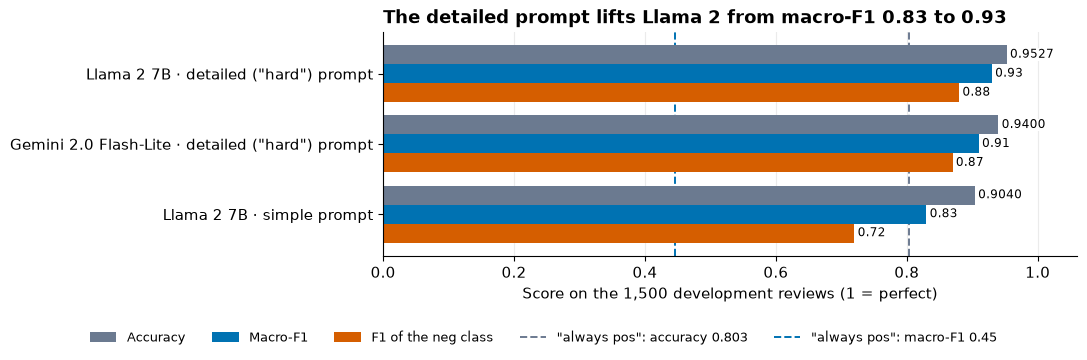

In [ ]:
# 🏆 LLM prompts on the development set: numbers copied from the reports of section 3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.plotting import apply_style, PALETTE

apply_style()

results = pd.DataFrame([
    # (model, accuracy, macro-F1, F1 of neg)
    ('Llama 2 7B · simple prompt',                       0.9040, 0.83, 0.72),
    ('Llama 2 7B · detailed ("hard") prompt',            0.9527, 0.93, 0.88),
    ('Gemini 2.0 Flash-Lite · detailed ("hard") prompt', 0.9400, 0.91, 0.87),
], columns=["model", "accuracy", "macro_f1", "f1_neg"])

# "Always say pos" baseline, from the support column of the reports (1,500 development reviews)
n_pos, n_neg = 1205, 295
base_acc = n_pos / (n_pos + n_neg)        # it is right for every pos and wrong for every neg
base_macro = (2 * base_acc / (1 + base_acc) + 0) / 2  # F1 of pos = 2PR/(P+R) with P=base_acc, R=1; F1 of neg = 0

# Best model at the top: sort by macro-F1 (ties broken by accuracy)
results = results.sort_values(["macro_f1", "accuracy"], ascending=False).reset_index(drop=True)
y = np.arange(len(results))

bars = [("accuracy", "Accuracy", PALETTE["grey"], 4),
        ("macro_f1", "Macro-F1", PALETTE["blue"], 2),
        ("f1_neg", "F1 of the neg class", PALETTE["red"], 2)]
h = 0.27  # height of one bar
fig, ax = plt.subplots(figsize=(11, 0.62 * len(results) + 1.4))
for k, (col, name, color, decimals) in enumerate(bars):
    pos = y + (k - 1) * h
    ax.barh(pos, results[col].fillna(0), height=h, color=color, label=name, zorder=2)
    for yi, v in zip(pos, results[col]):
        if pd.notna(v):
            ax.text(v + 0.005, yi, f"{v:.{decimals}f}", va="center", fontsize=8.5,
                    bbox=dict(facecolor="white", edgecolor="none", pad=0.3), zorder=3)
        elif col == "macro_f1":  # a missing value is shown as a note, never as a number
            ax.text(0.005, yi + h / 2, "macro-F1 and neg F1: not in the saved outputs", va="center",
                    fontsize=8.5, color=PALETTE["grey"], style="italic")

# The "always say pos" baseline (dashed lines, same colour as the metric they belong to)
ax.axvline(base_acc, color=PALETTE["grey"], ls="--", lw=1.4, zorder=1, label=f'"always pos": accuracy {base_acc:.3f}')
ax.axvline(base_macro, color=PALETTE["blue"], ls="--", lw=1.4, zorder=1, label=f'"always pos": macro-F1 {base_macro:.2f}')

ax.set_yticks(y, results["model"])
ax.set_ylim(y.max() + 0.6, y.min() - 0.6)  # reversed limits: first row at the top
ax.set_xlim(0, 1.06)
ax.set_xlabel('Score on the 1,500 development reviews (1 = perfect)')
ax.grid(axis="y", visible=False)
ax.set_title('The detailed prompt lifts Llama 2 from macro-F1 0.83 to 0.93')
fig.tight_layout()
handles, labels = ax.get_legend_handles_labels()  # the two dashed lines come first: move them to the end
fig.legend(handles[2:] + handles[:2], labels[2:] + labels[:2], loc="upper center", bbox_to_anchor=(0.5, 0.0),
           ncol=5, fontsize=9.5)
plt.show()

> 👀 **What to notice:**
> - **All three runs are far above both dashed lines** (accuracy 0.90–0.95 vs 0.803, macro-F1 0.83–0.93 vs 0.45), with no training at all.
> - **The prompt matters more than the model choice:** the same Llama 2 goes from macro-F1 0.83 (simple prompt) to **0.93** (detailed prompt), and its `neg` F1 from 0.72 to 0.88.
> - **Gemini and Llama 2 with the detailed prompt are close** (macro-F1 0.91 vs 0.93), but they err on opposite sides (see the reports above: Gemini almost never misses a negative review, but calls more positive reviews negative).
> - Remember the dataset is different (reviews are longer and written differently from tweets), so 0.95 here is not "better than the fine-tuned transformer" on tweets.

<a id="summary"></a>

## 📌 Summary

- A generative LLM can work as a **classifier without any training**: we describe the task in a prompt and parse its one-word answer.
- On 1,500 labelled laptop reviews: Llama-2 simple prompt **0.9040**, Llama-2 hard prompt **0.9527**, Gemini 2.0 flash lite hard prompt **0.9400** accuracy.
- **Prompt engineering** is real work: a role, explicit rules and one example cut Llama-2's errors from 144 to 71.
- The labelled *development* set is what lets us **measure** a prompt before trusting it on the unlabelled *challenge* set.
- Practical costs: an API is rate-limited and needs a key (keep it in an environment variable or a secret, **never** in the notebook); an open model needs a big GPU and a 13.5 GB download.
- Check the answer parsing: silent fallbacks (`'pos'` on errors) can hide failures.

**Next:** try to **fool** a sentiment model yourself in Challenge 1.

---
<div align="center">

⬅️ [Previous: 02.4 · Tweets: Transformers](02.4_Tweets_Transformers.ipynb) &nbsp;·&nbsp; 🏠 [Lesson 03](../../README.md) &nbsp;·&nbsp; [Next: 🎮 Challenge 1 · Flip It!](../03_challenge_flip_it/Challenge_1_Flip_It.ipynb) ➡️

**The AI Learning Hub** · Lesson 03 — Applied AI: unstructured data<br>
MIT License

</div>